In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from nilearn.datasets import fetch_atlas_harvard_oxford
from matplotlib import pyplot as plt
from scipy.stats import spearmanr

In [2]:
CONDITIONS = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]
STIMULUS = {condition: condition.split("_")[0] for condition in CONDITIONS}
SESSION = {condition: condition.split("_")[1] for condition in CONDITIONS}


# These are the two conditions whose stimulus matches the deprived need.
MOTIVATIONALLY_RELEVANT = {
    "food_fasting",
    "social_isolation",
}

In [5]:
def clean_roi_name(roi):
    """
    Remove a trailing .nii from ROI names while preserving spaces,
    commas, apostrophes, and underscores.
    """
    roi = str(roi).strip()

    if roi.endswith(".nii"):
        roi = roi[:-4]

    return roi

In [6]:
df = pd.read_csv('probing_rsa_fasting_social_isolation/results/rdms/rdm_metadata.csv')
df['roi'] = df['roi'].apply(clean_roi_name)
df

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Frontal Pole,False,5709,0.822385,"['run1', 'run2', 'run5', 'run6']"
1,sub-SAXSISO01,Insular Cortex,True,977,1.000000,"['run1', 'run2', 'run5', 'run6']"
2,sub-SAXSISO01,Superior Frontal Gyrus,False,2208,0.937978,"['run1', 'run2', 'run5', 'run6']"
3,sub-SAXSISO01,Middle Frontal Gyrus,True,2224,0.982332,"['run1', 'run2', 'run5', 'run6']"
4,sub-SAXSISO01,"Inferior Frontal Gyrus, pars triangularis",False,605,0.946792,"['run1', 'run2', 'run5', 'run6']"
...,...,...,...,...,...,...
2363,sub-SAXSISO42,HN,False,3,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2364,sub-SAXSISO42,HTH,True,133,0.963768,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2365,sub-SAXSISO42,MN,True,11,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2366,sub-SAXSISO42,STH,True,19,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"


In [7]:
# Lets add which dataset this roi came from so we wont mix them

midbrai_roi = roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "RN", "SNr", "PBP", "VeP", "HN", "HTH", "MN", "STH", "SNc_VTA"]

cortical_roi = fetch_atlas_harvard_oxford("cort-maxprob-thr0-2mm").labels
subcortical_roi = fetch_atlas_harvard_oxford("sub-maxprob-thr0-2mm").labels

cortical_roi.remove("Background")
subcortical_roi.remove("Background")

subcortical_roi = [roi.removeprefix("Left ").removeprefix("Right ") for roi in subcortical_roi]

[fetch_atlas_harvard_oxford] Dataset found in /home/anpa/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset found in /home/anpa/nilearn_data/fsl


In [8]:
df['atlas'] = np.where(df['roi'].isin(cortical_roi), 'cortical', 
                       np.where(df['roi'].isin(subcortical_roi), 'subcortical', 
                                np.where(df['roi'].isin(midbrai_roi), 'midbrain', 'unknown')))

In [9]:
df.atlas.value_counts()

atlas
cortical       1536
midbrain        480
subcortical     352
Name: count, dtype: int64

In [10]:
df.query('included').atlas.value_counts()

atlas
cortical       914
midbrain       423
subcortical    277
Name: count, dtype: int64

In [11]:
rdms = np.load('probing_rsa_fasting_social_isolation/results/rdms/crossnobis_rdms.npz')
rdms.keys()

KeysView(NpzFile 'probing_rsa_fasting_social_isolation/results/rdms/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions)

In [12]:
display(
    df.query('included').groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .sort_values(['atlas', 'n_participants'])
)


,atlas,roi,n_participants
13,cortical,"Lateral Occipital Cortex, superior division",1
16,cortical,"Middle Temporal Gyrus, temporooccipital part",1
26,cortical,Subcallosal Cortex,1
9,cortical,"Inferior Frontal Gyrus, pars triangularis",5
5,cortical,Frontal Medial Cortex,9
29,cortical,"Superior Temporal Gyrus, anterior division",9
30,cortical,"Superior Temporal Gyrus, posterior division",21
32,cortical,"Supramarginal Gyrus, anterior division",22
8,cortical,"Inferior Frontal Gyrus, pars opercularis",25
27,cortical,Superior Frontal Gyrus,28


In [11]:
# looking at this we should exclude roi with little participants rdms

excluded_rois = (
    df.query('included')
    .groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .query('n_participants < 20')  # for example, exclude ROIs with less than 5 participants
)
excluded_rois

,atlas,roi,n_participants
5,cortical,Frontal Medial Cortex,9
9,cortical,"Inferior Frontal Gyrus, pars triangularis",5
13,cortical,"Lateral Occipital Cortex, superior division",1
16,cortical,"Middle Temporal Gyrus, temporooccipital part",1
26,cortical,Subcallosal Cortex,1
29,cortical,"Superior Temporal Gyrus, anterior division",9


In [12]:
# Lets create model rdms

def make_pairwise_model(name, pair_function):
    """
    Construct a symmetric model RDM from a function that assigns a
    value to each pair of conditions.
    """
    model = pd.DataFrame(
        np.zeros((len(CONDITIONS), len(CONDITIONS))),
        index=CONDITIONS,
        columns=CONDITIONS,
        dtype=float,
    )

    for i, condition_1 in enumerate(CONDITIONS):
        for j in range(i + 1, len(CONDITIONS)):
            condition_2 = CONDITIONS[j]

            value = float(
                pair_function(condition_1, condition_2)
            )

            model.loc[condition_1, condition_2] = value
            model.loc[condition_2, condition_1] = value

    model.attrs["name"] = name
    return model


baseline_vs_deprived = make_pairwise_model(
    "baseline_vs_deprived",
    lambda a, b: (
        (SESSION[a] == 'baseline')
        !=
        (SESSION[b] == 'baseline')
    ),
)

isolation_vs_baseline_and_fasting = make_pairwise_model(
    "isolation_vs_baseline_and_fasting",
    lambda a, b: (
        (SESSION[a] == 'isolation')
        !=
        (SESSION[b] == 'isolation')
    ),
)

fasting_vs_baseline_and_isolation = make_pairwise_model(
    "fasting_vs_baseline_and_isolation",
    lambda a, b: (
        (SESSION[a] == 'fasting')
        !=
        (SESSION[b] == 'fasting')
    ),
)



social_vs_food_and_flowers = make_pairwise_model(
    "social_vs_food_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'social')
        !=
        (STIMULUS[b] == 'social')
    ),
)

food_vs_social_and_flowers = make_pairwise_model(
    "food_vs_social_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'food')
        !=
        (STIMULUS[b] == 'food')
    ),
)

flowers_vs_social_and_food = make_pairwise_model(
    "flowers_vs_social_and_food",
    lambda a, b: (
        (STIMULUS[a] == 'flowers')
        !=
        (STIMULUS[b] == 'flowers')
    ),
)


social_isolation_vs_rest_model = make_pairwise_model(
    "social_isolation_vs_rest",
    lambda a, b: (
        (a == 'social_isolation')
        !=
        (b == 'social_isolation')
    ),
)

food_fasting_vs_rest_model = make_pairwise_model(
    "food_fasting_vs_rest",
    lambda a, b: (
        (a == 'food_fasting')
        !=
        (b == 'food_fasting')
    ),
)

food_fasting_and_social_isolation_vs_rest = make_pairwise_model(
    "food_fasting_and_social_isolation_vs_rest",
    lambda a, b: (
        (a in ['food_fasting', 'social_isolation'])
        !=
        (b in ['food_fasting', 'social_isolation'])
    ),
)

In [13]:
#  Category-clustering models

    # 2.1 Stimulus family
        # social_vs_food_and_flowers
        # food_vs_social_and_flowers
        # flowers_vs_social_and_food

    # 2.2 Session family
        # baseline_vs_deprived
        # isolation_vs_baseline_and_fasting
        # fasting_vs_baseline_and_isolation

# Motivation deprivation models
    # social_isolation_vs_rest_model
    # food_fasting_vs_rest_model
    # food_fasting_and_social_isolation_vs_rest

MODEL_RDMS = {
    'social_vs_food_and_flowers': social_vs_food_and_flowers,
    'food_vs_social_and_flowers': food_vs_social_and_flowers,
    'flowers_vs_social_and_food': flowers_vs_social_and_food,

    'baseline_vs_deprived': baseline_vs_deprived,
    'isolation_vs_baseline_and_fasting': isolation_vs_baseline_and_fasting,
    'fasting_vs_baseline_and_isolation': fasting_vs_baseline_and_isolation,

    'social_isolation_vs_rest_model': social_isolation_vs_rest_model,
    'food_fasting_vs_rest_model': food_fasting_vs_rest_model,
    'food_fasting_and_social_isolation_vs_rest': food_fasting_and_social_isolation_vs_rest,
}

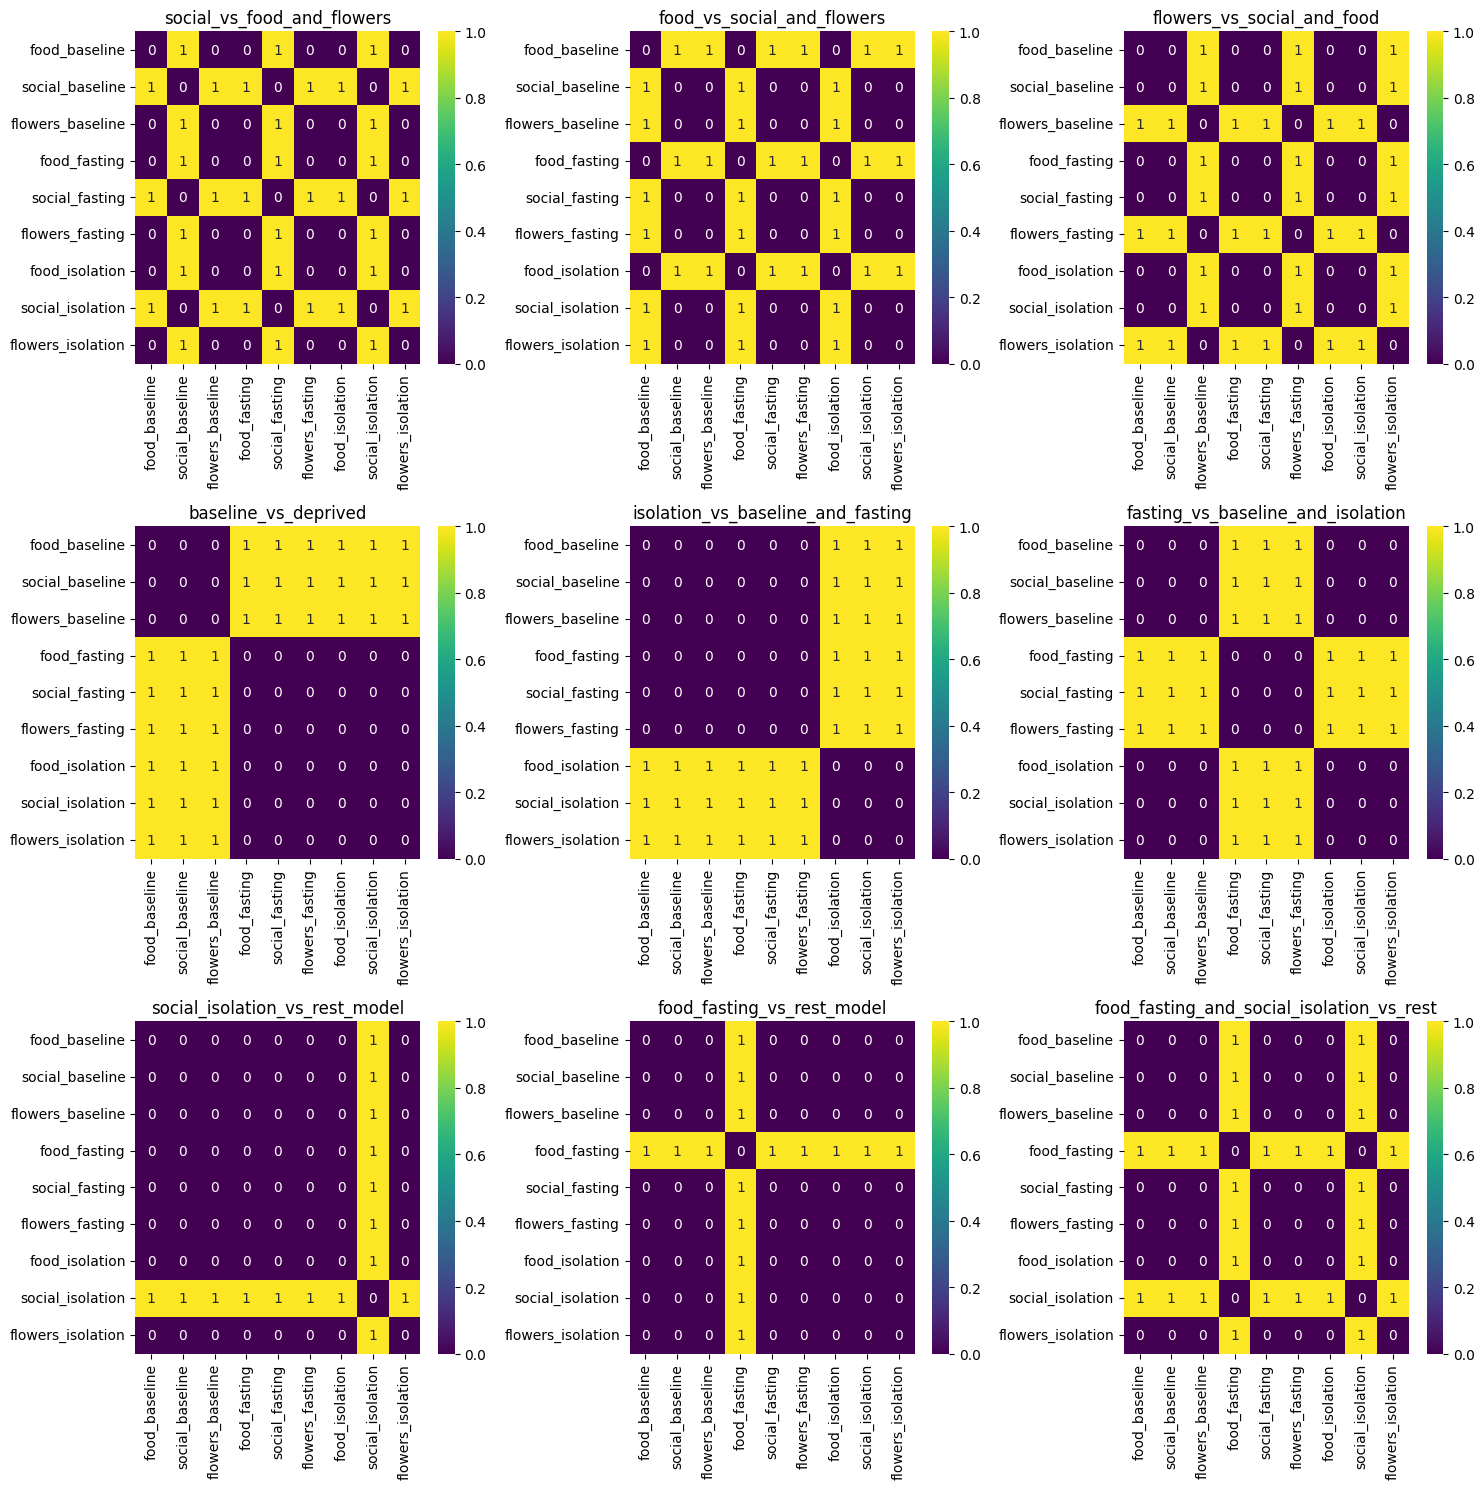

In [14]:
# plot all 9 RDMs on 3*3 grid

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (name, rdm) in zip(axes.flatten(), MODEL_RDMS.items()):
    sns.heatmap(rdm, annot=True, cmap="viridis", cbar=True, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [15]:
UPPER_TRIANGLE = np.triu_indices(
    len(CONDITIONS),
    k=1,
)

UPPER_TRIANGLE

(array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 6, 6, 7]),
 array([1, 2, 3, 4, 5, 6, 7, 8, 2, 3, 4, 5, 6, 7, 8, 3, 4, 5, 6, 7, 8, 4,
        5, 6, 7, 8, 5, 6, 7, 8, 6, 7, 8, 7, 8, 8]))

In [16]:
def vectorize_rdm(rdm):
    """
    Return the 36 unique off-diagonal entries of a 9 x 9 RDM.
    """
    ordered = rdm.loc[CONDITIONS, CONDITIONS]
    return ordered.to_numpy(dtype=float)[UPPER_TRIANGLE]

In [17]:
def compare_rdm_to_models(neural_rdm, model_rdms=MODEL_RDMS):
    neural_vector = vectorize_rdm(neural_rdm)

    return pd.Series(
        {
            name: stats.spearmanr(
                neural_vector,
                vectorize_rdm(model_rdm),
            )[0]
            for name, model_rdm in model_rdms.items()
        },
        name="spearman_rho",
    )

In [18]:
rdms["rdms"][list(rdms["subjects"]).index("sub-SAXSISO01"), list(rdms["rois"]).index("Pu.nii")]

array([[ 0.        ,  0.0501884 , -0.00102678,  0.05363569,  0.05038453,
         0.20948757,  0.32573402,  0.12635759,  0.15296879],
       [ 0.0501884 ,  0.        ,  0.01725196,  0.01909231,  0.00240232,
         0.05739799,  0.15682174,  0.02130025,  0.07626607],
       [-0.00102678,  0.01725196,  0.        ,  0.0202971 , -0.02474171,
         0.04477293,  0.24186863,  0.05753067,  0.101157  ],
       [ 0.05363569,  0.01909231,  0.0202971 ,  0.        ,  0.01250485,
         0.00589674,  0.04995241, -0.0402687 ,  0.02253497],
       [ 0.05038453,  0.00240232, -0.02474171,  0.01250485,  0.        ,
         0.0277144 ,  0.10195953, -0.05963177,  0.02111574],
       [ 0.20948757,  0.05739799,  0.04477293,  0.00589674,  0.0277144 ,
         0.        , -0.00731955, -0.1106239 , -0.0413376 ],
       [ 0.32573402,  0.15682174,  0.24186863,  0.04995241,  0.10195953,
        -0.00731955,  0.        ,  0.06033544,  0.01480729],
       [ 0.12635759,  0.02130025,  0.05753067, -0.0402687 , -0

In [28]:
excluded_rois.roi.to_list()

['Frontal Medial Cortex',
 'Inferior Frontal Gyrus, pars triangularis',
 'Lateral Occipital Cortex, superior division',
 'Middle Temporal Gyrus, temporooccipital part',
 'Subcallosal Cortex',
 'Superior Temporal Gyrus, anterior division']

In [29]:
# Calculate one rho per participant, ROI, and model.
model_vectors = {
    name: vectorize_rdm(model_rdm)
    for name, model_rdm in MODEL_RDMS.items()
}

score_rows = []

excluded_roi_list = excluded_rois.roi.to_list()
valid_df = df.query('included & roi not in @excluded_roi_list')


for atlas, subject, roi in valid_df[['atlas', 'subject', 'roi']].itertuples(index=False):
    neural_rdm = rdms["rdms"][list(rdms["subjects"]).index(subject), list(rdms["rois"]).index(f"{roi}.nii")]
    neural_vector = neural_rdm[UPPER_TRIANGLE]

    for model_name, model_vector in model_vectors.items():
        rho = stats.spearmanr(neural_vector, model_vector)[0]

        score_rows.append({
            "atlas": atlas,
            "subject": subject,
            "roi": roi,
            "model": model_name,
            "rho": rho,
        })

participant_scores = pd.DataFrame(score_rows)
participant_scores

,atlas,subject,roi,model,rho
0,cortical,sub-SAXSISO01,Insular Cortex,social_vs_food_and_flowers,0.299482
1,cortical,sub-SAXSISO01,Insular Cortex,food_vs_social_and_flowers,0.208568
2,cortical,sub-SAXSISO01,Insular Cortex,flowers_vs_social_and_food,-0.042783
3,cortical,sub-SAXSISO01,Insular Cortex,baseline_vs_deprived,0.310178
4,cortical,sub-SAXSISO01,Insular Cortex,isolation_vs_baseline_and_fasting,-0.262047
...,...,...,...,...,...
14287,midbrain,sub-SAXSISO42,SNc_VTA,isolation_vs_baseline_and_fasting,0.732662
14288,midbrain,sub-SAXSISO42,SNc_VTA,fasting_vs_baseline_and_isolation,-0.090914
14289,midbrain,sub-SAXSISO42,SNc_VTA,social_isolation_vs_rest_model,0.334453
14290,midbrain,sub-SAXSISO42,SNc_VTA,food_fasting_vs_rest_model,0.334453


In [30]:
participant_scores.roi.unique()

array(['Insular Cortex', 'Middle Frontal Gyrus',
       'Inferior Frontal Gyrus, pars opercularis',
       'Superior Temporal Gyrus, posterior division',
       'Superior Parietal Lobule',
       'Supramarginal Gyrus, posterior division', 'Angular Gyrus',
       'Intracalcarine Cortex',
       'Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex)',
       'Paracingulate Gyrus', 'Cingulate Gyrus, anterior division',
       'Cingulate Gyrus, posterior division', 'Precuneous Cortex',
       'Cuneal Cortex', 'Parahippocampal Gyrus, posterior division',
       'Lingual Gyrus', 'Temporal Occipital Fusiform Cortex',
       'Occipital Fusiform Gyrus', 'Frontal Opercular Cortex',
       'Central Opercular Cortex', 'Parietal Opercular Cortex',
       'Planum Polare', "Heschl's Gyrus (includes H1 and H2)",
       'Planum Temporale', 'Supracalcarine Cortex',
       'Cerebral White Matter', 'Lateral Ventricle', 'Thalamus',
       'Caudate', 'Putamen', 'Pallidum', 'Hippocampus', 'Amyg

In [31]:
behavioral_df = pd.read_csv('probing_rsa_fasting_social_isolation/dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))
behavioral_df.head()

,ID,Age,Gender,Monthly_Interactions,BMI,Close_Relationships,Loneliness_Score,rating_social_baseline,rating_food_baseline,rating_social_fasted,rating_food_fasted,rating_social_isolated,rating_food_isolated,Fasting_Craving1,Fasting_Craving2,Fasting_Craving3,Fasting_Craving4,Fasting_Craving5,Fasting_Craving6,Isolation_Craving1,Isolation_Craving2,Isolation_Craving3,Isolation_Craving4,Isolation_Craving5,Isolation_Craving6,Fasting_Hungry1,Fasting_Hungry2,Fasting_Hungry3,Fasting_Hungry4,Fasting_Hungry5,Fasting_Hungry6,Isolation_Lonely1,Isolation_Lonely2,Isolation_Lonely3,Isolation_Lonely4,Isolation_Lonely5,Isolation_Lonely6,ZMonthly_Interactions,ZClose_Relationships,ZMean_SocialNetwork,Dominance_Score,subject
0,SAX_SISO_01,20,female,40,23.17,17,42,6.555556,7.388889,7.333333,8.777778,7.555556,3.000000,73,77,84,84,94,,44,64,69,74,78,71,60,78,89,89,92,,45,44,60,40,41,47,-0.287937,0.929948,0.321006,23,sub-SAXSISO01
1,SAX_SISO_02,19,female,51,21.96,15,36,7.444444,7.388889,4.611111,8.333333,7.388889,7.333333,,,,78,91,96,50,50,55,55,55,55,,,,82,93,86,40,40,50,50,45,45,0.059165,0.538391,0.298778,22,sub-SAXSISO02
2,SAX_SISO_03,30,female,148,18.79,20,30,6.611111,6.055556,6.166667,10.000000,6.833333,4.111111,0,25,90,80,87,95,15,20,30,40,66,64,0,13,81,70,90,97,15,20,20,35,56,57,3.119974,1.517284,2.318629,22,sub-SAXSISO03
3,SAX_SISO_04,27,female,28,23.44,7,30,7.888889,8.833333,7.000000,8.888889,7.277778,5.944444,55,,,,85,87,60,57,37,54,60,64,0,,,,84,91,45,41,32,40,43,47,-0.666594,-1.027837,-0.847216,21,sub-SAXSISO04
4,SAX_SISO_05,19,female,83,19.69,20,34,6.055556,6.333333,5.583333,8.444444,7.666667,0.440000,57,41,58,71,75,79,33,65,80,80,90,90,0,5,45,57,76,74,31,35,40,40,40,50,1.068917,1.517284,1.293100,24,sub-SAXSISO05


In [32]:
behavioral_df = pd.read_csv('probing_rsa_fasting_social_isolation/dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))


participant_scores['Loneliness_Score'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Loneliness_Score'])
participant_scores['Close_Relationships'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Close_Relationships'])
participant_scores['Monthly_Interactions'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Monthly_Interactions'])
participant_scores['Isolation_Lonely6'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Isolation_Lonely6'])

participant_scores.head()

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Insular Cortex,social_vs_food_and_flowers,0.299482,42,17,40,47
1,cortical,sub-SAXSISO01,Insular Cortex,food_vs_social_and_flowers,0.208568,42,17,40,47
2,cortical,sub-SAXSISO01,Insular Cortex,flowers_vs_social_and_food,-0.042783,42,17,40,47
3,cortical,sub-SAXSISO01,Insular Cortex,baseline_vs_deprived,0.310178,42,17,40,47
4,cortical,sub-SAXSISO01,Insular Cortex,isolation_vs_baseline_and_fasting,-0.262047,42,17,40,47
